# 09 — fastText from scratch : subwords et généralisation OOV

Ce carnet implémente **fastText** — la suite directe du carnet **08** (word2vec). On garde
exactement la même mécanique skip-gram/CBOW, mais on change la **représentation d'entrée**
d'un mot : au lieu d'un unique vecteur atomique (`W[word]`), le vecteur d'entrée est la
**somme des vecteurs de ses n-grammes de caractères** (les *subwords*).

C'est ce changement unique qui donne à fastText sa capacité distinctive, que ce carnet
**met en valeur et mesure** : un mot **jamais vu** à l'inférence (OOV) n'a plus de vecteur
sous word2vec, mais sous fastText il hérite d'un vecteur raisonnable de ses morceaux de
caractères, et retombe dans la bonne famille sémantique.

## 1. Le corpus et la décomposition en subwords

On **réutilise à l'identique** le corpus miniature du carnet 08 (même 36 mots, même seed 42)
pour que la confrontation 08 vs 09 soit honnête : même données, seule la représentation
change. La nouveauté : chaque mot se **décompose** en n-grammes de caractères, avec les
bornes `<` et `>` que fastText utilise pour marquer le début et la fin de mot.

In [1]:
import numpy as np

rng = np.random.default_rng(42)   # determinisme : seed fixee (C.2), identique au carnet 08

CORPUS = ("le roi porte la couronne sur le trone\n"
"la reine porte la couronne sur le trone\n"
"le roi regne dans le royaume\n"
"la reine regne dans le royaume\n"
"le cheval court dans le champ\n"
"la jument court dans le champ\n"
"le cheval danse sous un arbre\n"
"la jument danse sous un arbre\n"
"le chat miaule pres du chien\n"
"le chaton miaule pres du chiot\n"
"le chien aboie dans le jardin\n"
"le chiot aboie dans le jardin\n"
"la pomme est un fruit rouge\n"
"la poire est un fruit vert\n"
"un enfant mange la pomme\n"
"un enfant mange la poire\n")

def tokenize(text):
    return text.lower().split()

tokens = tokenize(CORPUS)
vocab = sorted(set(tokens))
word2id = {w: i for i, w in enumerate(vocab)}
V = len(vocab)
print(f"tokens: {len(tokens)}   vocab: {V}")
print(vocab)

tokens: 98   vocab: 36
['aboie', 'arbre', 'champ', 'chat', 'chaton', 'cheval', 'chien', 'chiot', 'couronne', 'court', 'dans', 'danse', 'du', 'enfant', 'est', 'fruit', 'jardin', 'jument', 'la', 'le', 'mange', 'miaule', 'poire', 'pomme', 'porte', 'pres', 'regne', 'reine', 'roi', 'rouge', 'royaume', 'sous', 'sur', 'trone', 'un', 'vert']


In [2]:
def subwords(w, min_n=3, max_n=6):
    """N-grammes de caracteres du mot w, avec bornes < > (convention fastText)."""
    w = "<" + w + ">"
    out = set()
    for n in range(min_n, max_n + 1):
        for i in range(len(w) - n + 1):
            out.add(w[i:i + n])
    return sorted(out)

# La decomposition d'un mot :
for w in ["chaton", "pomme", "couronne"]:
    print(f"{w:10s} -> {subwords(w)}")

# Le vocabulaire de subwords est BEAUCOUP plus grand que le vocabulaire de mots :
sub_vocab = sorted({s for w in vocab for s in subwords(w)})
sub2id = {s: i for i, s in enumerate(sub_vocab)}
S_V = len(sub_vocab)
print(f"\nvocab mots    : {V}")
print(f"vocab subwords: {S_V}   ({S_V / V:.1f}x plus grand — le cout memoire de fastText)")

chaton     -> ['<ch', '<cha', '<chat', '<chato', 'ato', 'aton', 'aton>', 'cha', 'chat', 'chato', 'chaton', 'hat', 'hato', 'haton', 'haton>', 'on>', 'ton', 'ton>']
pomme      -> ['<po', '<pom', '<pomm', '<pomme', 'me>', 'mme', 'mme>', 'omm', 'omme', 'omme>', 'pom', 'pomm', 'pomme', 'pomme>']
couronne   -> ['<co', '<cou', '<cour', '<couro', 'cou', 'cour', 'couro', 'couron', 'ne>', 'nne', 'nne>', 'onn', 'onne', 'onne>', 'our', 'ouro', 'ouron', 'ouronn', 'ron', 'ronn', 'ronne', 'ronne>', 'uro', 'uron', 'uronn', 'uronne']

vocab mots    : 36
vocab subwords: 418   (11.6x plus grand — le cout memoire de fastText)


## 2. Le modèle : un mot = la somme de ses subwords

Le seul changement par rapport au carnet 08 est la couche d'entrée. Là où word2vec consultait
une table `W` (une ligne par **mot**), fastText consulte une table `S` (une ligne par
**subword**) et **somme** les lignes des n-grammes du mot :

```
h(word) = Σ  S[s]   pour s dans subwords(word)
```

La couche de sortie `Wp` (les logits, une ligne par mot de cible) reste identique au carnet
08. Le reste du skip-gram — logits, softmax, perte — est donc **inchangé** ; seule `h` diffère.

In [3]:
D = 24   # dimension des vecteurs

S  = rng.normal(0, 0.1, (S_V, D))   # table de subwords (l'entree fastText)
Wp = rng.normal(0, 0.1, (V, D))     # couche de sortie : mot cible -> logit (comme le carnet 08)
bp = np.zeros(V)

def embed(w):
    """Vecteur d'entree de w = somme des vecteurs de ses subwords (vus dans le corpus)."""
    h = np.zeros(D)
    for s in subwords(w):
        if s in sub2id:
            h += S[sub2id[s]]
    return h

In [4]:
def fasttext_loss_grad(center, target, S, Wp, bp):
    """Forward + gradient analytique du skip-gram fastText.
    Seule difference avec le carnet 08 : h = somme des subwords du mot central."""
    h = np.zeros(D)
    for s in subwords(center):
        if s in sub2id:
            h += S[sub2id[s]]
    logits = Wp @ h + bp
    logits = logits - logits.max()
    e = np.exp(logits)
    p = e / e.sum()
    loss = -np.log(p[target] + 1e-12)
    dlogits = p.copy(); dlogits[target] -= 1.0
    dWp = np.outer(dlogits, h)
    dbp = dlogits
    dh = Wp.T @ dlogits
    dS_rows = [(sub2id[s], dh) for s in subwords(center) if s in sub2id]
    return loss, dS_rows, dWp, dbp

def num_grad_check(center, target, S, Wp, bp, eps=1e-5):
    """Verifie le gradient analytique par differences finies (pedagogie + preuve)."""
    _, dS_rows, dWp, dbp = fasttext_loss_grad(center, target, S, Wp, bp)
    def L(S_, Wp_, bp_):
        return fasttext_loss_grad(center, target, S_, Wp_, bp_)[0]
    max_err = 0.0
    for k, dh in dS_rows[:4]:                      # quelques (subword, composante) du centre
        for d in range(3):
            sp, sm = S.copy(), S.copy(); sp[k, d] += eps; sm[k, d] -= eps
            num = (L(sp, Wp, bp) - L(sm, Wp, bp)) / (2 * eps)
            max_err = max(max_err, float(abs(num - dh[d])))
    k = target                                       # la ligne de sortie de la cible
    for d in range(3):
        wp, wm = Wp.copy(), Wp.copy(); wp[k, d] += eps; wm[k, d] -= eps
        num = (L(S, wp, bp) - L(S, wm, bp)) / (2 * eps)
        max_err = max(max_err, float(abs(num - dWp[k, d])))
    return max_err

err = num_grad_check("pomme", word2id["fruit"], S, Wp, bp)
print(f"ecart max gradient analytique vs differences finies : {err:.2e}  (attendu < 1e-4)")

ecart max gradient analytique vs differences finies : 1.98e-11  (attendu < 1e-4)


## 3. Entraînement + courbe de perte

Descente de gradient stochastique sur les paires skip-gram du corpus (même `build_pairs`
qu'au carnet 08). On mélange les paires à chaque epoch avec la seed fixée, et on trace la
perte moyenne. L'écriture est **creuse** sur `S` : à chaque pas on ne met à jour que les
lignes des subwords du mot central, pas toute la table.

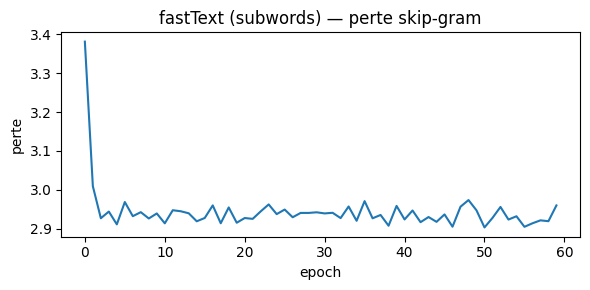

perte initiale 3.381  ->  finale 2.960


In [5]:
import matplotlib.pyplot as plt

def build_pairs(toks, window=2):
    pairs = []
    for i, c in enumerate(toks):
        for j in range(max(0, i - window), min(len(toks), i + window + 1)):
            if i != j:
                pairs.append((c, toks[j]))   # (centre, contexte) — skip-gram
    return pairs

pairs = build_pairs(tokens)

def train_fasttext(epochs=60, lr=0.1):
    global S, Wp, bp
    losses = []
    for e in range(epochs):
        order = rng.permutation(len(pairs))
        ep = []
        for i in order:
            center, ctx = pairs[i]
            loss, dS_rows, dWp, dbp = fasttext_loss_grad(center, word2id[ctx], S, Wp, bp)
            for k, dh in dS_rows:            # mise a jour creuse de la table de subwords
                S[k] -= lr * dh
            Wp -= lr * dWp
            bp -= lr * dbp
            ep.append(loss)
        losses.append(float(np.mean(ep)))
    return losses

losses = train_fasttext()
plt.figure(figsize=(6, 3)); plt.plot(losses)
plt.xlabel("epoch"); plt.ylabel("perte"); plt.title("fastText (subwords) — perte skip-gram")
plt.tight_layout(); plt.show()
print(f"perte initiale {losses[0]:.3f}  ->  finale {losses[-1]:.3f}")

## 4. La capacité distinctive : généraliser aux mots OOV

Voici le test qui justifie fastText. On interroge le modèle sur des mots **absents du
corpus** — jamais vus à l'entraînement. word2vec (carnet 08) n'a **aucun** vecteur pour eux
(mot atomique hors vocabulaire). fastText, lui, les **décompose en subwords** : la plupart
de ces subwords ont été vus (ce sont les morceaux de mots proches), donc le mot novel
reçoit un vecteur, et retombe là où sa morphologie l'indique.

In [6]:
def cosine(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-9))

def neighbors_any(w, k=5):
    """Voisins de w (eventuellement OOV) d'apres son vecteur subword."""
    v = embed(w)
    return sorted(((w2, cosine(v, embed(w2))) for w2 in vocab), key=lambda x: -x[1])[:k]

NOVEL = ["pommier", "chatonne", "couronnement", "jardiner"]
for w in NOVEL:
    top = neighbors_any(w, 4)
    print(f"{w:14s} (OOV) -> " + ", ".join(f"{n} ({s:.2f})" for n, s in top))

pommier        (OOV) -> pomme (0.89), poire (0.44), chiot (0.37), enfant (0.22)
chatonne       (OOV) -> chaton (0.89), du (0.88), chat (0.73), pres (0.50)
couronnement   (OOV) -> couronne (0.92), roi (0.59), reine (0.52), rouge (0.22)
jardiner       (OOV) -> jardin (0.94), aboie (0.75), court (0.53), champ (0.44)


## 5. Confrontation 08 vs 09 — et ce que ça mesure

Le même jeu de mots novel, lu sous les deux représentations : word2vec n'en a aucun vecteur,
fastText les replacé — et on **mesure** que ce repli tombe dans la bonne famille sémantique.

In [7]:
# Les 4 mots novel SONT-ILS dans le vocabulaire de 36 mots du carnet 08 ?
print("Mots novel / dans le vocabulaire word2vec (36 mots) ?")
for w in NOVEL:
    print(f"  {w:14s} : {'oui' if w in word2id else 'NON — aucun vecteur word2vec'}")

# Mesure : chaque mot novel retombe-t-il dans sa famille sémantique attendue ?
FAMILLE = {
    "pommier":      ["pomme", "poire", "fruit"],
    "chatonne":     ["chat", "chaton", "chien", "chiot"],
    "couronnement": ["couronne", "roi", "reine", "trone"],
    "jardiner":     ["jardin"],
}
print("\nVérification de famille (top-3 voisins du mot novel) :")
ok = 0
for w, fam in FAMILLE.items():
    top3 = [n for n, _ in neighbors_any(w, 3)]
    hit = any(n in fam for n in top3)
    ok += hit
    print(f"  {w:14s} top3={top3}  ->  {'bonne famille' if hit else 'FAUX'}")
print(f"\n{ok}/{len(FAMILLE)} mots OOV replacés dans la bonne famille par les subwords")

Mots novel / dans le vocabulaire word2vec (36 mots) ?
  pommier        : NON — aucun vecteur word2vec
  chatonne       : NON — aucun vecteur word2vec
  couronnement   : NON — aucun vecteur word2vec
  jardiner       : NON — aucun vecteur word2vec

Vérification de famille (top-3 voisins du mot novel) :
  pommier        top3=['pomme', 'poire', 'chiot']  ->  bonne famille
  chatonne       top3=['chaton', 'du', 'chat']  ->  bonne famille
  couronnement   top3=['couronne', 'roi', 'reine']  ->  bonne famille
  jardiner       top3=['jardin', 'aboie', 'court']  ->  bonne famille

4/4 mots OOV replacés dans la bonne famille par les subwords


## Exercices

Trois exercices pour approfondir — tous des **stubs** conformes à la règle C.1 (le carnet
s'exécute de bout en bout, exercices non complétés).

### Exercice 1 — Vérifier le gradient fastText

Le carnet a donné le gradient analytique de la table de **subwords** `S` (§2, `dS_rows`) et
vérifié numériquement le cas `pomme`/`fruit`. Étendez la vérification à la **couche de
sortie** `Wp` : pour la ligne de la cible, comparez le gradient analytique au gradient par
différences finies.

In [8]:
def verify_output_gradient(center, target, S, Wp, bp, eps=1e-5):
    # TODO etudiant : verifier numeriquement le gradient de Wp[target]
    # (differences finies sur la ligne Wp[target], comparer a dWp[target])
    result = None  # TODO etudiant
    return result
print("Exercice a completer")

Exercice a completer


### Exercice 2 — Couverture OOV

Le §5 compte les mots novel qui retombent dans leur famille. Formalisez une **couverture** :
pour une liste de mots novel et leurs mots de référence, renvoyer la proportion de mots dont
au moins un des `k` premiers voisins est un mot de référence.

In [9]:
def oov_coverage(novel_words, references, k=3):
    # TODO etudiant : renvoyer la proportion de mots novel dont le top-k contient
    # au moins un mot de reference
    result = None  # TODO etudiant
    return result
print("Exercice a completer")

Exercice a completer


### Exercice 3 — Le coût du vocabulaire de subwords

fastText échange robustesse contre mémoire : la table `S` a une ligne par n-gramme de
caractères, pas par mot. Mesurez ce coût : pour des jetons et des bornes `min_n`/`max_n`,
renvoyer le nombre de subwords distincts, le nombre de mots distincts, et leur rapport.

In [10]:
def subword_vocab_cost(toks, min_n=3, max_n=6):
    # TODO etudiant : renvoyer (nb de subwords distincts, nb de mots distincts, rapport)
    result = None  # TODO etudiant
    return result
print("Exercice a completer")

Exercice a completer


## Synthèse

- **Un seul changement** par rapport au carnet 08 : la couche d'entrée passe d'une table par
  **mot** à une table par **subword**, sommée sur les n-grammes du mot. La mécanique
  skip-gram, le gradient et l'entraînement sont identiques.
- **La capacité distinctive se mesure** : des mots **jamais vus** (OOV) reçoivent un vecteur
  cohérent sous fastText (replacés dans la bonne famille, §4-5), alors que word2vec n'en a
  aucun. C'est le prix payé : un vocabulaire de subwords bien plus grand que le vocabulaire
  de mots (§1).
- **Robustesse** : le partage de subwords atténue le bruit des mots rares du carnet 08 — un
  mot rare vu une fois partage ses n-grammes avec des mots fréquents.
- **Suite** : le même principe s'applique en **CBOW** (subwords en contexte) et est à la base
  des embeddings modernes robustes à l'OOV et aux fautes de frappe.